In [ ]:
# # installs for kaggle env difficulties 

# !apt-get update && apt-get install -y swig build-essential
# !pip install --upgrade setuptools wheel
# !pip install --no-build-isolation gymnasium[box2d] stable-baselines3[extra]

In [3]:
from stable_baselines3 import PPO
from stable_baselines3.common.env_util import make_vec_env
import os
import gymnasium as gym

from stable_baselines3 import PPO
from stable_baselines3.common.logger import configure
from stable_baselines3.common.vec_env import SubprocVecEnv
import pandas as pd 
import torch
from stable_baselines3.common.results_plotter import plot_results
from stable_baselines3.common import results_plotter
import matplotlib.pyplot as plt
import numpy as np
import pprint
import json
from stable_baselines3.common.evaluation import evaluate_policy
from stable_baselines3.common.callbacks import CheckpointCallback
from cnn import CustomCNN 


## Compute environment 
e.g how many cores? cuda or mps? 

In [4]:
print("CPU logical cores:", os.cpu_count())
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

print("Torch threads:", torch.get_num_threads())

CPU logical cores: 10
CUDA available: False
Torch threads: 4


## Model Training setup 
Edit vec_env and model before training 

In [5]:
model_dir = './256_feature_dim' # change this on new experiment 

log_dir = f'{model_dir}/env_logs/'
model_log_dir = f'{model_dir}/model_logs'
model_file = f'{model_dir}/ppo_racing.zip'
results_dir = f'./results/{model_dir}/'


## Train through PPO (don't run if just evaluating)

In [ ]:
num_timesteps = 1_000_000 # change this if needed

# change vec_env and model for new experiments 
vec_env = make_vec_env(
    "CarRacing-v3",
    monitor_dir=log_dir,
    n_envs=4, 
    seed=42, 
    vec_env_cls=SubprocVecEnv, 
    env_kwargs={"continuous": False, "render_mode": None}
)

policy_kwargs = dict(
    features_extractor_class=CustomCNN,
    features_extractor_kwargs=dict(features_dim=256), # 256 < 512, shrinking feature dim
)


model = PPO(
    "CnnPolicy",
    vec_env,
    verbose=1,
    ent_coef=0.01,
    seed=42, 
    device = "cuda" if torch.cuda.is_available() else "mps",
    policy_kwargs=policy_kwargs
)


def train(): 
    os.makedirs(log_dir, exist_ok=True)
    os.makedirs(model_log_dir, exist_ok=True)

    logger = configure(model_log_dir, ["stdout", "csv", "tensorboard"])

    checkpoint_callback = CheckpointCallback(
        save_freq=10000,
        save_path=model_dir,
        name_prefix="rl_model",
        save_replay_buffer=True,
        save_vecnormalize=True,
    )

    model.set_logger(logger)

    model.learn(total_timesteps=num_timesteps, callback=checkpoint_callback)

    model.save(f"{model_dir}/ppo_racing")
    vec_env.close()
    print("finished training")


train()

## Visualizing Training Rewards

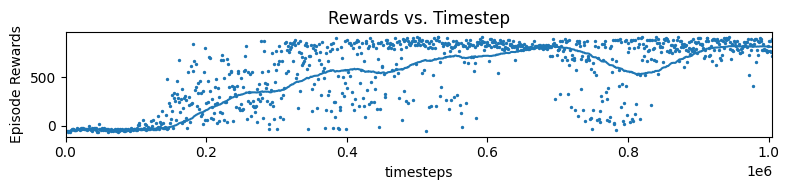

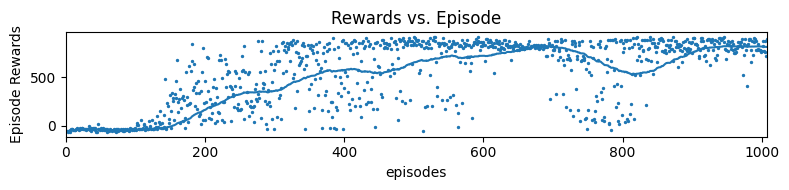

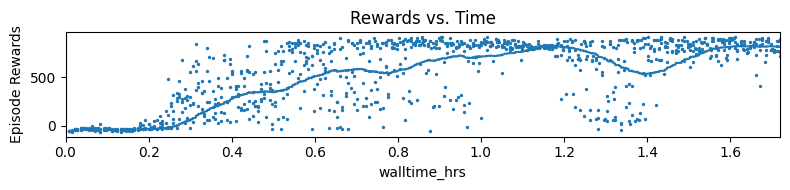

In [6]:
plot_results([log_dir], None, results_plotter.X_TIMESTEPS, "Rewards vs. Timestep")

plot_results([log_dir], None, results_plotter.X_EPISODES, "Rewards vs. Episode")

plot_results([log_dir], None, results_plotter.X_WALLTIME, "Rewards vs. Time")


## Visualizing RL Model Metrics During Training

Use tensorboard in terminal to visualize model training metrics. This should be done on the directory of model_log_dir.

In [7]:
df = pd.read_csv(f'{model_log_dir}/progress.csv')
print(df.head())

   time/iterations  time/fps  rollout/ep_len_mean  time/total_timesteps  \
0                1       170               1000.0                  8192   
1                2       165               1000.0                 16384   
2                3       164               1000.0                 24576   
3                4       164               1000.0                 32768   
4                5       163               1000.0                 40960   

   time/time_elapsed  rollout/ep_rew_mean  train/policy_gradient_loss  \
0                 48           -56.731040                         NaN   
1                 99           -47.958608                   -0.011827   
2                149           -41.791171                   -0.014695   
3                199           -40.028265                   -0.020186   
4                249           -38.112126                   -0.030690   

   train/learning_rate  train/value_loss  train/approx_kl  train/clip_range  \
0                  NaN         

## Load model after training 

In [6]:
model = PPO.load(model_file)
config = {
    "learning_rate": model.learning_rate,
    "n_steps": model.n_steps,
    "batch_size": model.batch_size,
    "n_epochs": model.n_epochs,
    "gamma": model.gamma,
    "gae_lambda": model.gae_lambda,
    "clip_range": model.clip_range,
    "ent_coef": model.ent_coef,
    "vf_coef": model.vf_coef,
    "max_grad_norm": model.max_grad_norm,
    "policy": model.policy.__class__.__name__,
    "policy_kwargs": model.policy_kwargs,
}

print(model.policy)

# uncomment to save params to json file 
with open(f"./{model_dir}/model.json", "w") as f:
    json.dump(config, f, indent=4, default=str)

ActorCriticCnnPolicy(
  (features_extractor): CustomCNN(
    (cnn): Sequential(
      (0): Conv2d(3, 32, kernel_size=(8, 8), stride=(4, 4))
      (1): ReLU()
      (2): Conv2d(32, 64, kernel_size=(4, 4), stride=(2, 2))
      (3): ReLU()
      (4): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1))
      (5): ReLU()
      (6): Flatten(start_dim=1, end_dim=-1)
    )
    (linear): Sequential(
      (0): Linear(in_features=4096, out_features=256, bias=True)
      (1): ReLU()
    )
  )
  (pi_features_extractor): CustomCNN(
    (cnn): Sequential(
      (0): Conv2d(3, 32, kernel_size=(8, 8), stride=(4, 4))
      (1): ReLU()
      (2): Conv2d(32, 64, kernel_size=(4, 4), stride=(2, 2))
      (3): ReLU()
      (4): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1))
      (5): ReLU()
      (6): Flatten(start_dim=1, end_dim=-1)
    )
    (linear): Sequential(
      (0): Linear(in_features=4096, out_features=256, bias=True)
      (1): ReLU()
    )
  )
  (vf_features_extractor): CustomCNN(
    (cnn): 

## Model Evalulation

In [7]:
# seperate env for eval
eval_env = gym.make(
    "CarRacing-v3",
    continuous=False,
    render_mode=None,
)

objc[6168]: Class SDLApplication is implemented in both /Users/alvint/Documents/personal_code/lap_zero/venv/lib/python3.9/site-packages/cv2/.dylibs/libSDL2-2.0.0.dylib (0x12a358890) and /Users/alvint/Documents/personal_code/lap_zero/venv/lib/python3.9/site-packages/pygame/.dylibs/libSDL2-2.0.0.dylib (0x12e2252c8). This may cause spurious casting failures and mysterious crashes. One of the duplicates must be removed or renamed.
objc[6168]: Class SDLAppDelegate is implemented in both /Users/alvint/Documents/personal_code/lap_zero/venv/lib/python3.9/site-packages/cv2/.dylibs/libSDL2-2.0.0.dylib (0x12a3588e0) and /Users/alvint/Documents/personal_code/lap_zero/venv/lib/python3.9/site-packages/pygame/.dylibs/libSDL2-2.0.0.dylib (0x12e225318). This may cause spurious casting failures and mysterious crashes. One of the duplicates must be removed or renamed.
objc[6168]: Class SDLTranslatorResponder is implemented in both /Users/alvint/Documents/personal_code/lap_zero/venv/lib/python3.9/site-pac

In [12]:
# evaluates rewards across specified eval episodes 
eval_determ = evaluate_policy(
    model,
    eval_env,
    n_eval_episodes=1,
    deterministic=True,
    return_episode_rewards=True
)

eval_stoch = evaluate_policy(
    model,
    eval_env,
    n_eval_episodes=1,
    deterministic=False,
    return_episode_rewards=True
)

df_d = pd.DataFrame({
    # "episodes": range(1, 101), 
    "episodes": [1], 
    "rewards": eval_determ[0],
    "ep_len": eval_determ[1] 
})

df_s = pd.DataFrame({
    # "episodes": range(1, 101), 
    "episodes": [1], 
    "rewards": eval_stoch[0],
    "ep_len": eval_stoch[1] 
})


df_d.to_csv(f'{results_dir}/eval_determ.csv', index=False)
df_s.to_csv(f'{results_dir}/eval_stoch.csv', index=False)



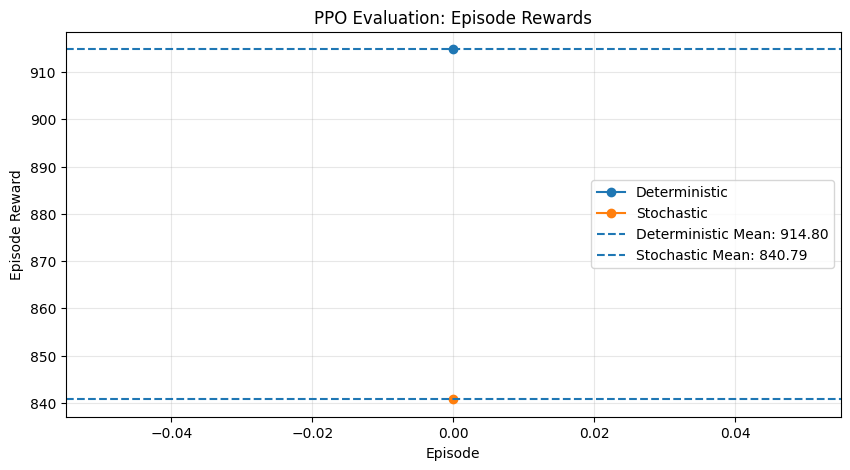

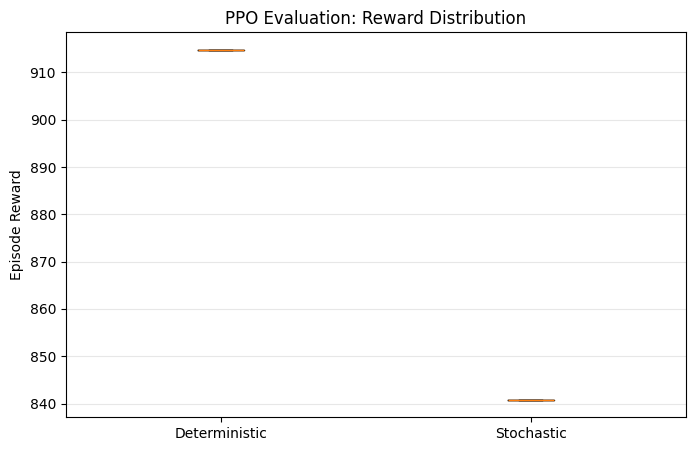

NameError: name 'det_lengths' is not defined

<Figure size 1000x500 with 0 Axes>

In [ ]:
# det_rewards, det_lengths = eval_determ
# stoch_rewards, stoch_lengths = eval_stoch

deterministic = pd.read_csv(f'{results_dir}/eval_determ.csv')
stochastic = pd.read_csv(f'{results_dir}/eval_stoch.csv')
det_rewards = deterministic['rewards']
det_lengths = deterministic['ep_len']
stoch_rewards = stochastic['rewards']
stoch_lengths = stochastic['ep_len']

# reward plots
plt.figure(figsize=(10, 5))
plt.plot(det_rewards, marker="o", label="Deterministic")
plt.plot(stoch_rewards, marker="o", label="Stochastic")

plt.axhline(np.mean(det_rewards), linestyle="--",
            label=f"Deterministic Mean: {np.mean(det_rewards):.2f}")
plt.axhline(np.mean(stoch_rewards), linestyle="--",
            label=f"Stochastic Mean: {np.mean(stoch_rewards):.2f}")

plt.xlabel("Episode")
plt.ylabel("Episode Reward")
plt.title("PPO Evaluation: Episode Rewards")
plt.legend()
plt.grid(alpha=0.3)
plt.savefig('./img/baseline_ep_reward')
plt.show()

# reward distribution
plt.figure(figsize=(8, 5))

plt.boxplot(
    [det_rewards, stoch_rewards],
    tick_labels=["Deterministic", "Stochastic"]
)

plt.ylabel("Episode Reward")
plt.title("PPO Evaluation: Reward Distribution")
plt.grid(axis="y", alpha=0.3)
plt.show()

# episode length plots 
plt.figure(figsize=(10, 5))
plt.plot(det_lengths, marker="o", label="Deterministic")
plt.plot(stoch_lengths, marker="o", label="Stochastic")
plt.xlabel("Episode")
plt.ylabel("Episode Length (Steps)")
plt.title("PPO Evaluation: Episode Lengths")
plt.legend()
plt.grid(alpha=0.3)
plt.show()